## 1) Load the dataset and Read it.

In [1]:
# All Liberales that we youse it :

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sqlalchemy import create_engine

In [2]:
# here read the dataset and but it in "data" variable:

data = pd.read_excel('Carrefour_new_2013_to_2023_products .xlsx')

In [3]:
# To Show All of Colums.
pd.set_option('display.max_columns', None)

In [4]:
# Read the first 10 rows fron the data:

data.head(10)

,order_id,order_date,status,item_id,product_name,qty_ordered,price,value,discount_percent,selling_price,shipping_cost,expenses,profit,category,sub_category,payment_method,year,month,gender,age,city,shipping_mode,gross_profit,net_gross_profit
0,20130101001,2013-01-01,Pending,6714,Milk,6,383.43,2300.58,0.13,333.58,30.60,5.38,328.20,Grocery,Dairy Products,Cash on Delivery,2013,1,Female,31,Cairo,Express Shipping,1969.20,1938.60
1,20130101002,2013-01-01,Shipped,4702,Clocks,8,6982.34,55858.72,0.32,4747.99,19.72,6.02,4741.97,Home & Kitchen,Home Decor,Credit Card,2013,1,Female,20,Giza,Express Shipping,37935.76,37916.04
2,20130101003,2013-01-01,Delivered,2814,Swimsuit,3,372.57,1117.71,0.39,227.27,47.73,19.01,208.26,Clothing,Women's Clothing,Credit Card,2013,1,Male,23,Cairo,Standard Shipping,624.78,577.05
3,20130101004,2013-01-01,Shipped,3369,Canon EOS RP,6,4423.09,26538.54,0.16,3715.40,45.06,8.09,3707.31,Electronics,Cameras,Debit Card,2013,1,Male,53,Alexandria,Standard Shipping,22243.86,22198.80
4,20130101005,2013-01-01,Delivered,9429,TCL Roku TV,5,61367.62,306838.10,0.05,58299.24,20.62,14.95,58284.29,Electronics,Televisions,Debit Card,2013,1,Male,20,Giza,Standard Shipping,291421.45,291400.83
5,20130101006,2013-01-01,Shipped,4618,Lenovo ThinkPad,5,31934.03,159670.15,0.02,31295.35,26.12,18.60,31276.75,Electronics,Laptops,Debit Card,2013,1,Male,31,Alexandria,Express Shipping,156383.75,156357.63
6,20130101007,2013-01-01,Delivered,1838,Shorts,1,235.57,235.57,0.44,131.92,41.95,9.27,122.65,Clothing,Women's Clothing,Debit Card,2013,1,Male,54,Giza,Standard Shipping,122.65,80.70
7,20130101008,2013-01-01,Pending,9946,Blueberry,2,80.69,161.38,0.28,58.10,46.01,18.11,39.99,Grocery,Fruits & Vegetables,Cash on Delivery,2013,1,Female,23,Cairo,Express Shipping,79.98,33.97
8,20130101009,2013-01-01,Pending,5906,Jeans,3,264.53,793.59,0.15,224.85,25.72,19.09,205.76,Clothing,Kids' Clothing,Credit Card,2013,1,Female,48,Cairo,Standard Shipping,617.28,591.56
9,20130101010,2013-01-01,Delivered,3990,LG OLED,6,66700.67,400204.02,0.38,41354.42,10.36,9.55,41344.87,Electronics,Televisions,Debit Card,2013,1,Female,24,Alexandria,Express Shipping,248069.22,248058.86


In [5]:
# See the shape of the Dataset:

print("The Shape of the Dataset is: ", data.shape)

The Shape of the Dataset is:  (130272, 24)


In [6]:
# See the data type of all Colunms:

data.dtypes

order_id              int64
order_date           object
status               object
item_id               int64
product_name         object
qty_ordered           int64
price               float64
value               float64
discount_percent    float64
selling_price       float64
shipping_cost       float64
expenses            float64
profit              float64
category             object
sub_category         object
payment_method       object
year                  int64
month                 int64
gender               object
age                   int64
city                 object
shipping_mode        object
gross_profit        float64
net_gross_profit    float64
dtype: object

In [7]:
# See where is the nulls in the data:

data.isnull().sum()


order_id            0
order_date          0
status              0
item_id             0
product_name        0
qty_ordered         0
price               0
value               0
discount_percent    0
selling_price       0
shipping_cost       0
expenses            0
profit              0
category            0
sub_category        0
payment_method      0
year                0
month               0
gender              0
age                 0
city                0
shipping_mode       0
gross_profit        0
net_gross_profit    0
dtype: int64

In [8]:
print("The total of Nulls is: ", data.isnull().sum().sum())


The total of Nulls is:  0


In [9]:
# See if there is any Dublicates:

print("Duplicated rows:", data.duplicated().sum())

Duplicated rows: 12149


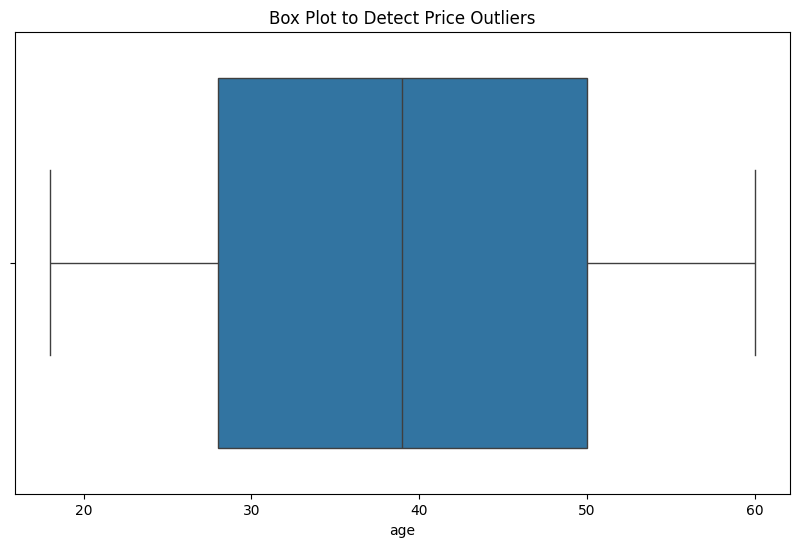

In [10]:
# See the Outliers in the data

plt.figure(figsize=(10, 6))
sns.boxplot(x = data['age'])  # <-------- see eatch numerical Column.
plt.title('Box Plot to Detect Price Outliers')
plt.show()

## 2) Start Cleaning.

In [11]:
# Here we Drop the Duplicates from the data:

print("Num of Rows before cleaning:", len(data))
print("*" * 40)

data = data.drop_duplicates().reset_index(drop=True)
print("Num Rows after removing duplicates:", len(data))

Num of Rows before cleaning: 130272
****************************************
Num Rows after removing duplicates: 118123


In [12]:
# 2) Convert order_date to datetime:

data["order_date"] = pd.to_datetime(data["order_date"])

In [13]:
# See the range of the Dates:

print("Date range:", data["order_date"].min().date(), "to", data["order_date"].max().date())


Date range: 2013-01-01 to 2023-09-30


## 3) Create the Fact & Dim tables.

In [14]:
# 1) Create "Dim Product" Table:

dim_product = data[['product_name', 'category', 'sub_category']].drop_duplicates().reset_index(drop=True)
dim_product['product_id'] = dim_product.index + 1

# Link with the Main Table
data = data.merge(dim_product, on=['product_name', 'category', 'sub_category'], how='left')

In [15]:
# 2) Create "Dim Customer" Table:

dim_customer = data[['gender', 'age', 'city']].drop_duplicates().reset_index(drop=True)
dim_customer['customer_id'] = dim_customer.index + 1

# Link with the Main Table
data = data.merge(dim_customer, on=['gender', 'age', 'city'], how='left')

In [16]:
# 3) Create "Dim Date" Table:

dim_date = data[['order_date']].drop_duplicates().reset_index(drop=True)
dim_date['date'] = dim_date['order_date']
dim_date['year'] = dim_date['order_date'].dt.year
dim_date['month'] = dim_date['order_date'].dt.month
dim_date['quarter'] = dim_date['order_date'].dt.quarter
dim_date['day_name'] = dim_date['order_date'].dt.day_name()
dim_date = dim_date[['date', 'year', 'month', 'quarter', 'day_name']].drop_duplicates().reset_index(drop=True)

In [17]:
# 4) Create "Dim Shapping" Table: الشحن

dim_shipping = data[['shipping_mode', 'shipping_cost']].drop_duplicates().reset_index(drop=True)
dim_shipping['shipping_id'] = dim_shipping.index + 1

# Link with the Main Table
data = data.merge(dim_shipping, on=['shipping_mode', 'shipping_cost'], how='left')

In [18]:
# 5) The "Fact orders" table:

fact_orders = data[[
    'order_id', 
    'order_date',             # ForenKey From Dim_Date
    'product_id',             # ForenKey From Dim_Product
    'customer_id',            # ForenKey From Dim_Customer
    'shipping_id',            # ForenKey From Dim_Shipping
    'status', 
    'payment_method', 
    'qty_ordered', 
    'price', 
    'discount_percent', 
    'selling_price', 
    'value', 
    'expenses', 
    'profit', 
    'gross_profit', 
    'net_gross_profit'
]].copy()


fact_orders = fact_orders.drop_duplicates(subset=['order_id', 'product_id']).reset_index(drop=True)

In [19]:
fact_orders.head()

,order_id,order_date,product_id,customer_id,shipping_id,status,payment_method,qty_ordered,price,discount_percent,selling_price,value,expenses,profit,gross_profit,net_gross_profit
0,20130101001,2013-01-01,1,1,1,Pending,Cash on Delivery,6,383.43,0.13,333.58,2300.58,5.38,328.20,1969.20,1938.60
1,20130101002,2013-01-01,2,2,2,Shipped,Credit Card,8,6982.34,0.32,4747.99,55858.72,6.02,4741.97,37935.76,37916.04
2,20130101003,2013-01-01,3,3,3,Delivered,Credit Card,3,372.57,0.39,227.27,1117.71,19.01,208.26,624.78,577.05
3,20130101004,2013-01-01,4,4,4,Shipped,Debit Card,6,4423.09,0.16,3715.40,26538.54,8.09,3707.31,22243.86,22198.80
4,20130101005,2013-01-01,5,5,5,Delivered,Debit Card,5,61367.62,0.05,58299.24,306838.10,14.95,58284.29,291421.45,291400.83


In [20]:
# Save eatch Table to CSV type.

# dim_product.to_csv('Dim_Product.csv', index=False)
# dim_customer.to_csv('Dim_Customer.csv', index=False)
# dim_date.to_csv('Dim_Date.csv', index=False)
# dim_shipping.to_csv('Dim_Shipping.csv', index=False)
# fact_orders.to_csv('Fact_Orders.csv', index=False)

# print("Done!")

## 4) Load the data to MySQL DataBase.

In [ ]:

# 1) Setting up contact information for MySQL
user = 'root'
password = '  ' 
host = 'localhost'
port = '3306'
db_name = 'carrefour_db'        


engine = create_engine(f'mysql+pymysql://{user}:{password}@{host}:{port}/{db_name}')

# 2) Upload each separate table to MySQL
dim_product.to_sql('Dim_Product', con=engine, if_exists='replace', index=False)
dim_customer.to_sql('Dim_Customer', con=engine, if_exists='replace', index=False)
dim_date.to_sql('Dim_Date', con=engine, if_exists='replace', index=False)
dim_shipping.to_sql('Dim_Shipping', con=engine, if_exists='replace', index=False)
fact_orders.to_sql('Fact_Orders', con=engine, if_exists='replace', index=False, chunksize=5000)

print("تم رفع جميع الجداول بنجاح إلى قاعدة بيانات MySQL!")